# Case iFood — Part 1  
## Baselines clássicos: Regressão Logística, Decision Tree e Random Forest

Neste notebook vamos:

- preparar os dados do case
- criar alguns atributos simples
- treinar **3 modelos base**
- comparar os resultados com **threshold 0.5**
- escolher também um **melhor threshold de negócio**
- salvar um histórico simplificado de experimentos para reaproveitar nos próximos notebooks

### Foco do projeto
O objetivo do projeto é **priorizar precision**, sem abrir mão de um **recall aceitável**.  
Isso faz sentido porque **não há verba para prospectar toda a base de clientes**.

In [17]:

# Se necessário, instale bibliotecas ausentes
# !pip install pyarrow

In [18]:

import os
import json
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score,
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, roc_curve, auc
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

SEED = 42
np.random.seed(SEED)

ARTIFACTS_DIR = "artifacts"
HISTORY_PARQUET = os.path.join(ARTIFACTS_DIR, "experiments_history.parquet")
HISTORY_CSV = os.path.join(ARTIFACTS_DIR, "experiments_history.csv")

os.makedirs(ARTIFACTS_DIR, exist_ok=True)

## 1. Leitura dos dados
Ajuste o caminho abaixo, se necessário.

In [19]:

# Ajuste o caminho se necessário
DATA_PATH = "data.csv"

df = pd.read_csv(DATA_PATH)
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,0,0,0,0,0,0,3,11,0


## 2. Visão geral e feature engineering
Mantemos a mesma linha didática do case, criando atributos simples e fáceis de interpretar.

In [20]:

df = df.copy()

# Exemplo clássico do case iFood:
# ajuste as colunas caso os nomes estejam diferentes na sua base
if "Year_Birth" in df.columns:
    df["Age"] = 2024 - df["Year_Birth"]

if "Dt_Customer" in df.columns:
    df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], errors="coerce")
    if df["Dt_Customer"].notna().any():
        ref_date = df["Dt_Customer"].max()
        df["Days_Customer"] = (ref_date - df["Dt_Customer"]).dt.days

df = df.convert_dtypes()
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Days_Customer
0,5524,1957,Graduation,Single,58138,0,0,2012-09-04,58,635,...,0,0,0,0,0,3,11,1,67,663
1,2174,1954,Graduation,Single,46344,1,1,2014-03-08,38,11,...,0,0,0,0,0,3,11,0,70,113
2,4141,1965,Graduation,Together,71613,0,0,2013-08-21,26,426,...,0,0,0,0,0,3,11,0,59,312
3,6182,1984,Graduation,Together,26646,1,0,2014-02-10,26,11,...,0,0,0,0,0,3,11,0,40,139
4,5324,1981,PhD,Married,58293,1,0,2014-01-19,94,173,...,0,0,0,0,0,3,11,0,43,161


## 3. Definição da variável-alvo
Neste case vamos assumir a coluna `Response` como target.

In [21]:

TARGET = "Response"

X_raw = df.drop(columns=[TARGET, "Dt_Customer"])
y = df[TARGET].copy()

print("Shape de X:", X_raw.shape)
print("Distribuição da target:")
print(y.value_counts(normalize=True))

Shape de X: (2240, 29)
Distribuição da target:
Response
0    0.850893
1    0.149107
Name: proportion, dtype: Float64


## 4. Split treino e teste
Usamos estratificação para manter a proporção da classe positiva.

In [22]:

Xtrain_raw, Xtest_raw, ytrain, ytest = train_test_split(
    X_raw, y,
    test_size=0.2,
    stratify=y,
    random_state=SEED
)

print(Xtrain_raw.shape, Xtest_raw.shape)

(1792, 29) (448, 29)


## 5. Tipos de variáveis e pré-processamento

### Regressão Logística
- precisa de variáveis numéricas
- costuma se beneficiar de **normalização**
- precisa de **One-Hot Encoding** para variáveis categóricas

### Decision Tree / Random Forest
- não exigem normalização
- ainda precisam de dados numéricos, então usaremos **One-Hot Encoding**
- são menos sensíveis à escala das variáveis

In [23]:

cat_cols = Xtrain_raw.select_dtypes(include=["object", "string", "category", "boolean"]).columns.tolist()
num_cols = [c for c in Xtrain_raw.columns if c not in cat_cols]

print("Numéricas:", len(num_cols))
print("Categóricas:", len(cat_cols))

Numéricas: 27
Categóricas: 2


In [24]:

numeric_pipe_log = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

numeric_pipe_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_log = ColumnTransformer([
    ("num", numeric_pipe_log, num_cols),
    ("cat", categorical_pipe, cat_cols)
])

preprocessor_tree = ColumnTransformer([
    ("num", numeric_pipe_tree, num_cols),
    ("cat", categorical_pipe, cat_cols)
])

## 6. Funções auxiliares
Aqui criamos um histórico **simplificado** de experimentos.

### Campos do histórico
- `run_date`
- `notebook_part`
- `model_name`
- `experiment_type`
- `threshold_label` (`default_0.5` ou `best_business_threshold`)
- `threshold`
- `precision`
- `recall`
- `f1`
- `auc`

Observação: **descartamos thresholds intermediários**.  
Em cada modelo salvaremos apenas:
1. o resultado com **threshold 0.5**
2. o resultado com o **melhor threshold de negócio**

In [25]:

def load_history():
    if os.path.exists(HISTORY_PARQUET):
        try:
            return pd.read_parquet(HISTORY_PARQUET)
        except Exception:
            pass
    if os.path.exists(HISTORY_CSV):
        return pd.read_csv(HISTORY_CSV)
    cols = [
        "run_date", "notebook_part", "model_name", "experiment_type",
        "threshold_label", "threshold", "precision", "recall", "f1", "auc"
    ]
    return pd.DataFrame(columns=cols)

def save_history(df_hist):
    try:
        df_hist.to_parquet(HISTORY_PARQUET, index=False)
        print(f"Histórico salvo em parquet: {HISTORY_PARQUET}")
    except Exception as e:
        print(f"Parquet indisponível ({e}). Salvando também em CSV.")
    df_hist.to_csv(HISTORY_CSV, index=False)
    print(f"Histórico salvo em CSV: {HISTORY_CSV}")

def metricas_classificacao(y_true, y_proba, threshold=0.5):
    y_pred = (y_proba >= threshold).astype(int)
    return {
        "threshold": threshold,
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "auc": roc_auc_score(y_true, y_proba),
        "accuracy": accuracy_score(y_true, y_pred)
    }

def escolher_melhor_threshold_negocio(y_true, y_proba, recall_min=0.50, thresholds=None):
    if thresholds is None:
        thresholds = np.round(np.arange(0.30, 0.81, 0.01), 2)
    resultados = []
    for t in thresholds:
        m = metricas_classificacao(y_true, y_proba, threshold=t)
        resultados.append(m)
    df_thr = pd.DataFrame(resultados)
    candidatos = df_thr[df_thr["recall"] >= recall_min].copy()
    if len(candidatos) == 0:
        melhor = df_thr.sort_values(["precision", "recall"], ascending=False).iloc[0]
    else:
        melhor = candidatos.sort_values(["precision", "recall", "f1"], ascending=False).iloc[0]
    return df_thr, melhor

def registrar_modelo(hist_df, notebook_part, model_name, experiment_type, metricas_default, metricas_best):
    linhas = []
    for label, m in [("default_0.5", metricas_default), ("best_business_threshold", metricas_best)]:
        linhas.append({
            "run_date": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
            "notebook_part": notebook_part,
            "model_name": model_name,
            "experiment_type": experiment_type,
            "threshold_label": label,
            "threshold": float(m["threshold"]),
            "precision": float(m["precision"]),
            "recall": float(m["recall"]),
            "f1": float(m["f1"]),
            "auc": float(m["auc"])
        })
    hist_df = pd.concat([hist_df, pd.DataFrame(linhas)], ignore_index=True)
    return hist_df

## 7. Baseline 1 — Regressão Logística

### Conceito
A regressão logística é um modelo linear para classificação.  
Ela aprende uma combinação linear das variáveis e transforma esse resultado em probabilidade.

### Hiperparâmetros principais
- `C`: controla a regularização
- `class_weight`: ajuda em bases desbalanceadas
- `max_iter`: número máximo de iterações

In [26]:

log_model = Pipeline([
    ("preprocessor", preprocessor_log),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=SEED
    ))
])

log_model.fit(Xtrain_raw, ytrain)
log_proba = log_model.predict_proba(Xtest_raw)[:, 1]

log_default = metricas_classificacao(ytest, log_proba, threshold=0.5)
log_thr_df, log_best = escolher_melhor_threshold_negocio(ytest, log_proba, recall_min=0.50)

pd.DataFrame([log_default, log_best], index=["threshold_0.5", "best_business_threshold"])

,threshold,precision,recall,f1,auc,accuracy
threshold_0.5,0.50,0.448276,0.776119,0.568306,0.89944,0.823661
best_business_threshold,0.73,0.631579,0.537313,0.580645,0.89944,0.883929


## 8. Baseline 2 — Decision Tree

### Conceito
A árvore de decisão cria regras do tipo **se-então**, particionando o espaço dos dados.

### Hiperparâmetros principais
- `max_depth`: profundidade máxima
- `min_samples_split`: mínimo para dividir um nó
- `min_samples_leaf`: mínimo por folha

### Premissas de dados
- não precisa normalizar
- precisa transformar categorias em números

In [27]:

dt_model = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=SEED
    ))
])

dt_model.fit(Xtrain_raw, ytrain)
dt_proba = dt_model.predict_proba(Xtest_raw)[:, 1]

dt_default = metricas_classificacao(ytest, dt_proba, threshold=0.5)
dt_thr_df, dt_best = escolher_melhor_threshold_negocio(ytest, dt_proba, recall_min=0.50)

pd.DataFrame([dt_default, dt_best], index=["threshold_0.5", "best_business_threshold"])

,threshold,precision,recall,f1,auc,accuracy
threshold_0.5,0.50,0.463415,0.283582,0.351852,0.792964,0.843750
best_business_threshold,0.62,0.545455,0.268657,0.360000,0.792964,0.857143


## 9. Baseline 3 — Random Forest

### Conceito
Random Forest é um conjunto de várias árvores treinadas sobre amostras e subconjuntos de variáveis.

### Hiperparâmetros principais
- `n_estimators`: quantidade de árvores
- `max_depth`: profundidade máxima
- `min_samples_split` e `min_samples_leaf`
- `max_features`: quantidade de variáveis por divisão

In [28]:

rf_model = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=10,
        min_samples_leaf=4,
        class_weight="balanced_subsample",
        random_state=SEED,
        n_jobs=-1
    ))
])

rf_model.fit(Xtrain_raw, ytrain)
rf_proba = rf_model.predict_proba(Xtest_raw)[:, 1]

rf_default = metricas_classificacao(ytest, rf_proba, threshold=0.5)
rf_thr_df, rf_best = escolher_melhor_threshold_negocio(ytest, rf_proba, recall_min=0.50)

pd.DataFrame([rf_default, rf_best], index=["threshold_0.5", "best_business_threshold"])

,threshold,precision,recall,f1,auc,accuracy
threshold_0.5,0.50,0.666667,0.447761,0.535714,0.892976,0.883929
best_business_threshold,0.46,0.625000,0.522388,0.569106,0.892976,0.881696


## 10. Comparação dos baselines

In [29]:

baseline_compare = pd.DataFrame([
    {"model_name": "logistic_regression", **log_default},
    {"model_name": "decision_tree", **dt_default},
    {"model_name": "random_forest", **rf_default},
]).sort_values(["precision", "recall"], ascending=False)

baseline_compare

,model_name,threshold,precision,recall,f1,auc,accuracy
2,random_forest,0.5,0.666667,0.447761,0.535714,0.892976,0.883929
1,decision_tree,0.5,0.463415,0.283582,0.351852,0.792964,0.843750
0,logistic_regression,0.5,0.448276,0.776119,0.568306,0.899440,0.823661


## 11. Gráfico de Precision e Recall por threshold
Esse gráfico ajuda a justificar a escolha do melhor threshold de negócio.

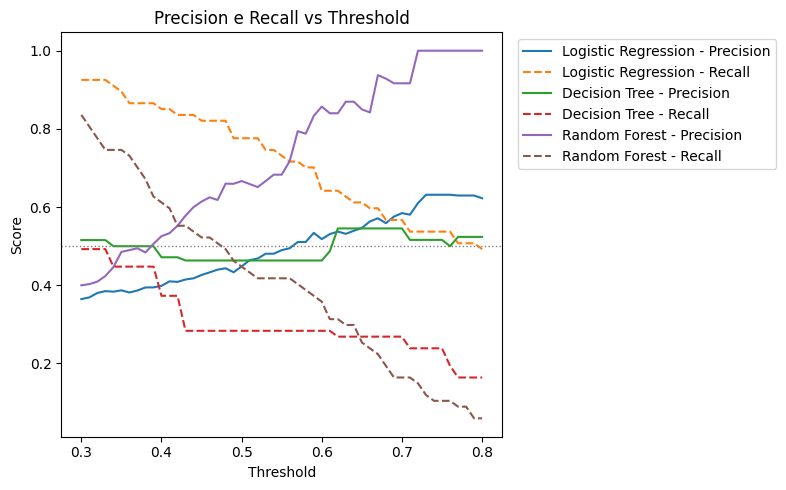

In [30]:

plt.figure(figsize=(8,5))
for nome, df_thr in [
    ("Logistic Regression", log_thr_df),
    ("Decision Tree", dt_thr_df),
    ("Random Forest", rf_thr_df)
]:
    plt.plot(df_thr["threshold"], df_thr["precision"], label=f"{nome} - Precision")
    plt.plot(df_thr["threshold"], df_thr["recall"], linestyle="--", label=f"{nome} - Recall")

plt.axhline(0.50, color="gray", linestyle=":", linewidth=1)
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision e Recall vs Threshold")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 12. Registro simplificado do histórico
Salvamos apenas:
- threshold 0.5
- melhor threshold de negócio

In [31]:

history = load_history()
history = registrar_modelo(history, "part1", "logistic_regression", "baseline", log_default, log_best)
history = registrar_modelo(history, "part1", "decision_tree", "baseline", dt_default, dt_best)
history = registrar_modelo(history, "part1", "random_forest", "baseline", rf_default, rf_best)

save_history(history)
history.tail(6)

Histórico salvo em parquet: artifacts\experiments_history.parquet
Histórico salvo em CSV: artifacts\experiments_history.csv


,run_date,notebook_part,model_name,experiment_type,threshold_label,threshold,precision,recall,f1,auc
6,2026-03-12 00:19:45,part1,logistic_regression,baseline,default_0.5,0.50,0.448276,0.776119,0.568306,0.899440
7,2026-03-12 00:19:45,part1,logistic_regression,baseline,best_business_threshold,0.73,0.631579,0.537313,0.580645,0.899440
8,2026-03-12 00:19:45,part1,decision_tree,baseline,default_0.5,0.50,0.463415,0.283582,0.351852,0.792964
9,2026-03-12 00:19:45,part1,decision_tree,baseline,best_business_threshold,0.62,0.545455,0.268657,0.360000,0.792964
10,2026-03-12 00:19:45,part1,random_forest,baseline,default_0.5,0.50,0.666667,0.447761,0.535714,0.892976
11,2026-03-12 00:19:45,part1,random_forest,baseline,best_business_threshold,0.46,0.625000,0.522388,0.569106,0.892976


## 13. Persistência dos dados para os próximos notebooks
Isso ajuda a reaproveitar o split e manter a sequência didática.

In [32]:

Xtrain_raw.to_parquet(os.path.join(ARTIFACTS_DIR, "Xtrain_raw.parquet"), index=False)
Xtest_raw.to_parquet(os.path.join(ARTIFACTS_DIR, "Xtest_raw.parquet"), index=False)
ytrain.to_frame(name=TARGET).to_parquet(os.path.join(ARTIFACTS_DIR, "ytrain.parquet"), index=False)
ytest.to_frame(name=TARGET).to_parquet(os.path.join(ARTIFACTS_DIR, "ytest.parquet"), index=False)

print("Arquivos salvos em artifacts/")

Arquivos salvos em artifacts/


## 14. Leitura didática dos resultados

Ao final do Part 1, já conseguimos responder:
- como um modelo linear se comporta neste problema
- como uma única árvore se comporta
- como um ensemble simples de árvores se comporta

No **Part 2**, seguiremos para a **família de boosting**:
- LightGBM
- XGBoost
- CatBoost